<a href="https://colab.research.google.com/github/AashiSrivastava411/Iris-Species-Classification/blob/main/model_iris.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
from sklearn.datasets import load_iris
iris = load_iris()

X = iris.data
y = iris.target

feature_names = iris.feature_names
target_names = iris.target_names

print("Feature names:", feature_names)
print("Target names:", target_names)

print("\nType of X is:", type(X))

print("\nFirst 5 rows of X:\n", X[:5])

Feature names: ['sepal length (cm)', 'sepal width (cm)', 'petal length (cm)', 'petal width (cm)']
Target names: ['setosa' 'versicolor' 'virginica']

Type of X is: <class 'numpy.ndarray'>

First 5 rows of X:
 [[5.1 3.5 1.4 0.2]
 [4.9 3.  1.4 0.2]
 [4.7 3.2 1.3 0.2]
 [4.6 3.1 1.5 0.2]
 [5.  3.6 1.4 0.2]]


In [ ]:
from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.4, random_state=1)

In [ ]:
print("X_train Shape:",  X_train.shape)
print("X_test Shape:", X_test.shape)
print("Y_train Shape:", y_train.shape)
print("Y_test Shape:", y_test.shape)

X_train Shape: (90, 4)
X_test Shape: (60, 4)
Y_train Shape: (90,)
Y_test Shape: (60,)


In [ ]:
#Training model using logistic regression
from sklearn.linear_model import LogisticRegression
log_reg = LogisticRegression(max_iter=200)
log_reg.fit(X_train, y_train)

LogisticRegression(max_iter=200)

In [ ]:
#making prediction
y_pred = log_reg.predict(X_test)

In [ ]:
#evaluating model accuracy

from sklearn import metrics
print("Logistic Regression model accuracy:", metrics.accuracy_score(y_test, y_pred))

Logistic Regression model accuracy: 0.9666666666666667


In [ ]:
#model making prediction on new sample data
sample = [[3, 5, 4, 2], [2, 3, 5, 4]]
preds = log_reg.predict(sample)
pred_species = [iris.target_names[p] for p in preds]
print("Predictions:", pred_species)

Predictions: [np.str_('virginica'), np.str_('virginica')]


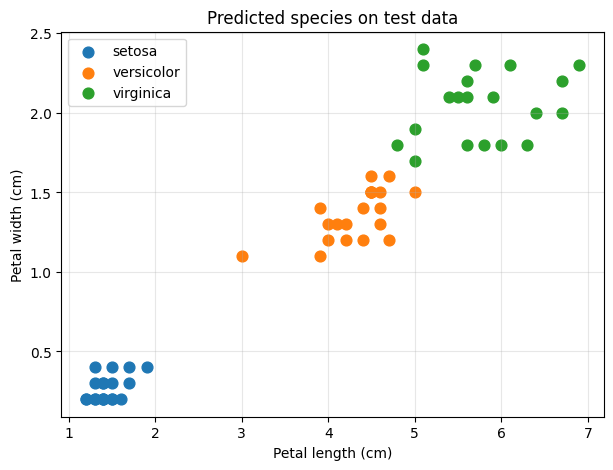

In [ ]:
import matplotlib.pyplot as plt

plt.figure(figsize=(7,5))
for i , name in enumerate(target_names):
    mask = y_pred == i
    plt.scatter(X_test[mask,2],X_test[mask,3], label=name,s=60)
plt.xlabel("Petal length (cm)")
plt.ylabel("Petal width (cm)")
plt.title("Predicted species on test data")
plt.legend()
plt.grid(alpha= 0.3)
plt.show()


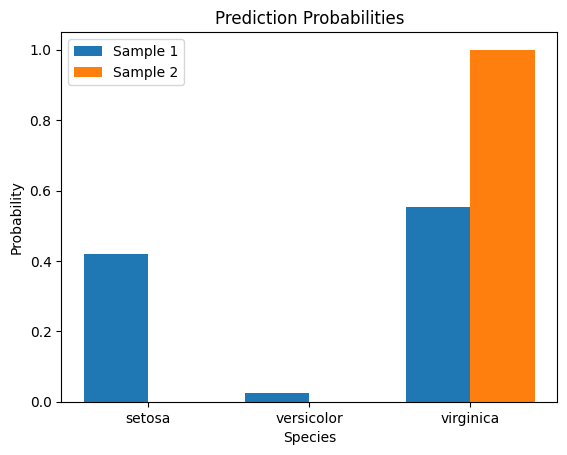

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

probs = log_reg.predict_proba(sample)
x = np.arange(3)
plt.bar(x - 0.2, probs[0], width=0.4, label="Sample 1")
plt.bar(x + 0.2, probs[1], width=0.4, label="Sample 2")
plt.xticks(x, iris.target_names)
plt.xlabel("Species")
plt.ylabel("Probability")
plt.title("Prediction Probabilities")
plt.legend()
plt.show()

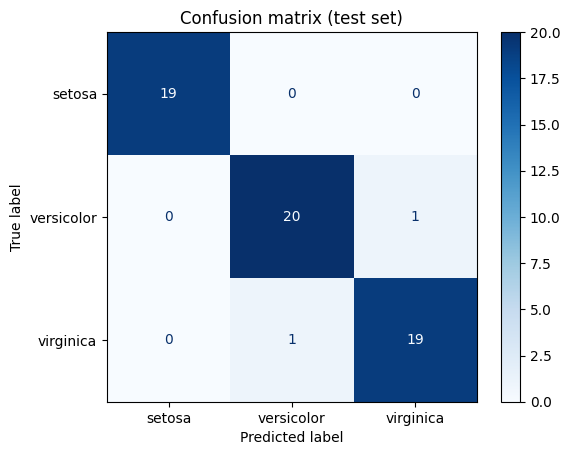

              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        19
  versicolor       0.95      0.95      0.95        21
   virginica       0.95      0.95      0.95        20

    accuracy                           0.97        60
   macro avg       0.97      0.97      0.97        60
weighted avg       0.97      0.97      0.97        60



In [ ]:
import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay, classification_report

ConfusionMatrixDisplay.from_predictions(y_test, y_pred, display_labels=target_names, cmap="Blues")
plt.title("Confusion matrix (test set)")
plt.show()

print(classification_report(y_test, y_pred, target_names=target_names))